<a href="https://colab.research.google.com/github/Trainbow-7/sleep-dectector/blob/main/notebooks/wakewatch_training.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# WakeWatch: Sleep and Drowsiness Detection
### Model training and evaluation

**Project:** WakeWatch is a camera-based system that flags when a student or staff member appears drowsy or asleep and announces an alert.
**Organisation:** Bitnox Solution, Machine Learning programme project.
**Purpose of this notebook:** train and evaluate the image classifier used by the WakeWatch detector.

| | |
|---|---|
| **Task** | Three-class image classification: awake, drowsy, sleeping |
| **Own data** | Photographs of nine participants, organised by participant |
| **Public data** | CEW (Closed Eyes in the Wild): faces with eyes open or closed, used for pre-training |
| **Model** | MobileNetV2 backbone (ImageNet weights) with a small classification head |
| **Evaluation** | Zero-shot test, fixed person-level split, and leave-one-person-out cross-validation |
| **Inputs** | `clean.zip` (prepared own data) and a CEW archive (`cew*.zip`) in the Google Drive folder named in the settings cell |
| **Runtime** | Google Colab with a GPU (T4) |

**Contents**
1. Setup
2. Data
3. Model
4. Stage 1: eye-state pre-training on CEW
5. Stage 2: zero-shot evaluation on own participants
6. Stage 3: fine-tuning for three classes
7. Leave-one-person-out evaluation
8. Summary and limitations
9. Export
10. References

## 1. Setup

In [14]:
import os, json, glob, random, zipfile
from pathlib import Path
import numpy as np
import pandas as pd
from PIL import Image
import matplotlib.pyplot as plt
import tensorflow as tf
import keras
from keras import layers
from sklearn.metrics import (classification_report, confusion_matrix,
                             ConfusionMatrixDisplay, accuracy_score, f1_score)

# ---------------------------------------------------------------- settings
DRIVE_FOLDER = "wakewatch"     # Google Drive folder that holds clean.zip and the CEW zip
IMG = 224                      # input resolution
BATCH = 16
SEED = 42
CLASSES = ["awake", "drowsy", "sleeping"]
IMAGENET = "imagenet"          # pre-trained weights for the backbone
EPOCHS_CEW_HEAD = 5            # pre-training: classification head only
EPOCHS_CEW_FINE = 5            # pre-training: head plus top backbone layers
EPOCHS_OWN_HEAD = 15           # own data: classification head only
EPOCHS_OWN_FINE = 10           # own data: head plus top backbone layers
FINE_TUNE_LAYERS = 30          # number of top backbone layers unfrozen during fine-tuning
SHOW_SAMPLES = False           # True displays participant photos; clear notebook outputs before sharing

keras.utils.set_random_seed(SEED)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "axes.titleweight": "bold",
                     "font.size": 10})
PALETTE = {"awake": "#1b9e77", "drowsy": "#d95f02", "sleeping": "#7570b3"}

FIG_DIR = Path("outputs/figures")
FIG_DIR.mkdir(parents=True, exist_ok=True)


def savefig(name):
    plt.savefig(FIG_DIR / name, dpi=150, bbox_inches="tight")


print("TensorFlow", tf.__version__, "| Keras", keras.__version__)
print("GPU devices:", [d.name for d in tf.config.list_physical_devices("GPU")] or "none (training will be slow)")

TensorFlow 2.21.0 | Keras 3.13.2
GPU devices: ['/physical_device:GPU:0']


In [15]:
from google.colab import drive
drive.mount("/content/drive")
DRIVE = f"/content/drive/MyDrive/{DRIVE_FOLDER}"
DATA = "/content/data"

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [16]:
def find_zip(prefix):
    """Locate an input archive in the Drive folder by name prefix, with a helpful error."""
    folder = Path(DRIVE)
    if not folder.is_dir():
        raise FileNotFoundError(
            f"Drive folder '{DRIVE_FOLDER}' not found. Folders in My Drive: "
            f"{sorted(p.name for p in folder.parent.iterdir() if p.is_dir())[:30]}")
    hits = sorted(folder.glob(f"{prefix}*.zip"))
    if not hits:
        raise FileNotFoundError(
            f"No '{prefix}*.zip' in '{DRIVE_FOLDER}'. Files found: {sorted(p.name for p in folder.iterdir())}")
    return hits[0]


os.makedirs(DATA, exist_ok=True)
for prefix in ["clean", "cew"]:
    archive = find_zip(prefix)
    with zipfile.ZipFile(archive) as z:
        z.extractall(DATA)
    print("Extracted", archive.name)

OWN = Path(DATA) / "clean"
assert (OWN / "train").exists(), "clean.zip must contain clean/train, clean/val and clean/test"

# The CEW folder is the one that contains both an 'open' and a 'closed' sub-folder.
cew_hits = [Path(p).parent for p in glob.glob(f"{DATA}/**/open", recursive=True)
            if (Path(p).parent / "closed").is_dir()]
assert cew_hits, "The CEW archive must contain 'open' and 'closed' folders"
CEW = cew_hits[0]
print(f"CEW: {len(list((CEW / 'open').glob('*')))} open, {len(list((CEW / 'closed').glob('*')))} closed images")

Extracted clean.zip
Extracted cew.zip
CEW: 1231 open, 1192 closed images


## 2. Data

Each participant's photographs are stored with the participant identifier in the file name (for example `p01_awake_...`). The identifier is used to keep participants separate during evaluation, so a model is never tested on a person it was trained on.

Photographs of participants are personal data. They are used only for this project and are not published.

77 images from 9 participants

class   awake  drowsy  sleeping
person                         
p01         4       3         4
p02         2       1         3
p03         3       2         3
p04         3       4         3
p05         4       3         3
p06         2       3         3
p07         2       4         3
p08         4       3         0
p09         2       3         3 

class  awake  drowsy  sleeping
split                         
test       6       4         3
train     16      19        18
val        4       3         4


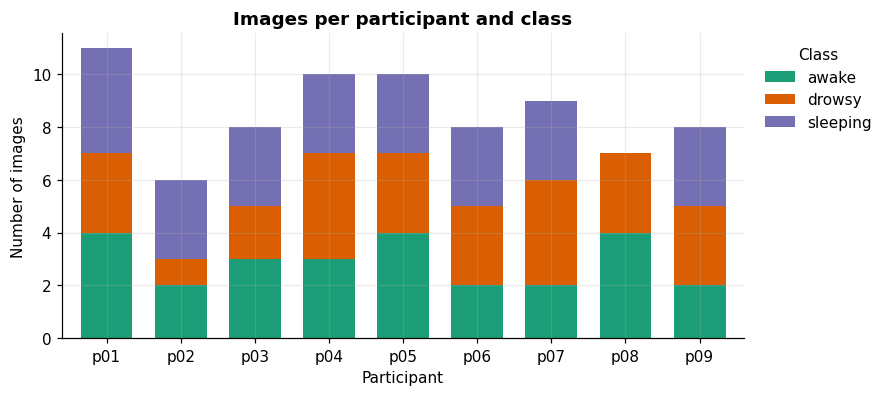

In [17]:
def load_own():
    X, y, persons, splits = [], [], [], []
    for split in ["train", "val", "test"]:
        for ci, c in enumerate(CLASSES):
            d = OWN / split / c
            if not d.exists():
                continue
            for f in sorted(d.glob("*.jpg")):
                img = Image.open(f).convert("RGB").resize((IMG, IMG))
                X.append(np.asarray(img, dtype=np.uint8))
                y.append(ci)
                persons.append(f.name.split("_")[0].lower())
                splits.append(split)
    return np.stack(X), np.array(y), np.array(persons), np.array(splits)


X, y, persons, splits = load_own()
df = pd.DataFrame({"person": persons, "class": [CLASSES[i] for i in y], "split": splits})
print(f"{len(X)} images from {df['person'].nunique()} participants\n")

counts = df.pivot_table(index="person", columns="class", values="split",
                        aggfunc="count", fill_value=0).reindex(columns=CLASSES, fill_value=0)
print(counts.to_string(), "\n")
print(df.pivot_table(index="split", columns="class", values="person",
                     aggfunc="count", fill_value=0).reindex(columns=CLASSES, fill_value=0).to_string())

ax = counts.plot(kind="bar", stacked=True, color=[PALETTE[c] for c in CLASSES], figsize=(8, 3.6), width=0.7)
ax.set_title("Images per participant and class")
ax.set_xlabel("Participant"); ax.set_ylabel("Number of images")
ax.legend(title="Class", frameon=False, bbox_to_anchor=(1.01, 1), loc="upper left")
plt.xticks(rotation=0); savefig("data_distribution.png"); plt.show()

In [18]:
if SHOW_SAMPLES:
    rng = np.random.default_rng(SEED)
    fig, axes = plt.subplots(3, 5, figsize=(10, 6.4))
    for r, c in enumerate(CLASSES):
        pick = rng.choice(np.where(y == r)[0], size=min(5, int((y == r).sum())), replace=False)
        for k in range(5):
            axes[r, k].axis("off")
            if k < len(pick):
                axes[r, k].imshow(X[pick[k]])
                axes[r, k].set_title(f"{c} ({persons[pick[k]]})", fontsize=9, color=PALETTE[c])
    plt.tight_layout(); plt.show()
else:
    print("Sample display is off (SHOW_SAMPLES = False).")

Sample display is off (SHOW_SAMPLES = False).


## 3. Model

With only a small number of own images, training a network from scratch is not practical. The approach uses transfer learning:

- **Backbone:** MobileNetV2, a compact network pre-trained on ImageNet, which already encodes general visual features.
- **Head:** global average pooling, dropout (0.3) and a dense output layer.
- **Augmentation:** random horizontal flip, rotation, zoom, brightness and contrast, applied during training only.
- **Fine-tuning:** the head is trained first with the backbone frozen; then the top backbone layers are unfrozen at a low learning rate. Batch-normalisation layers stay frozen.

In [19]:
augment = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.08),
    layers.RandomZoom(0.1),
    layers.RandomBrightness(0.2, value_range=(0, 255)),
    layers.RandomContrast(0.2),
], name="augment")   # active during training only


def make_backbone():
    return keras.applications.MobileNetV2(
        input_shape=(IMG, IMG, 3), include_top=False, weights=IMAGENET, pooling="avg")


def build_model(base, n_out, activation):
    inp = keras.Input((IMG, IMG, 3))
    x = augment(inp)
    x = keras.applications.mobilenet_v2.preprocess_input(x)
    x = base(x)
    x = layers.Dropout(0.3)(x)
    out = layers.Dense(n_out, activation=activation)(x)
    return keras.Model(inp, out)


def set_trainable(base, n_last):
    """Freeze the backbone except its last n_last layers (batch-norm layers stay frozen)."""
    base.trainable = n_last > 0
    n = len(base.layers)
    for i, layer in enumerate(base.layers):
        layer.trainable = (n_last > 0 and i >= n - n_last
                           and not isinstance(layer, layers.BatchNormalization))

## 4. Stage 1: eye-state pre-training on CEW

The public CEW dataset contains face images labelled as eyes open or eyes closed. The model is first trained on this binary task so that it learns eye-state features before seeing the project's own photographs.

CEW has no participant identifiers, so its validation accuracy only confirms that training works. It is not a measure of performance on WakeWatch data.

Found 2423 files belonging to 2 classes.
Using 2060 files for training.
Found 2423 files belonging to 2 classes.
Using 363 files for validation.
Epoch 1/5
129/129 - 11s - 85ms/step - accuracy: 0.9500 - loss: 0.1585 - val_accuracy: 1.0000 - val_loss: 0.0300
Epoch 2/5
129/129 - 5s - 41ms/step - accuracy: 0.9956 - loss: 0.0325 - val_accuracy: 1.0000 - val_loss: 0.0174
Epoch 3/5
129/129 - 10s - 79ms/step - accuracy: 0.9971 - loss: 0.0205 - val_accuracy: 1.0000 - val_loss: 0.0108
Epoch 4/5
129/129 - 10s - 80ms/step - accuracy: 0.9971 - loss: 0.0151 - val_accuracy: 1.0000 - val_loss: 0.0081
Epoch 5/5
129/129 - 10s - 79ms/step - accuracy: 0.9971 - loss: 0.0125 - val_accuracy: 1.0000 - val_loss: 0.0064
Epoch 1/5
129/129 - 13s - 98ms/step - accuracy: 0.9990 - loss: 0.0026 - val_accuracy: 1.0000 - val_loss: 3.4987e-04
Epoch 2/5
129/129 - 6s - 46ms/step - accuracy: 0.9981 - loss: 0.0041 - val_accuracy: 1.0000 - val_loss: 2.5522e-04
Epoch 3/5
129/129 - 6s - 46ms/step - accuracy: 1.0000 - loss: 5.9

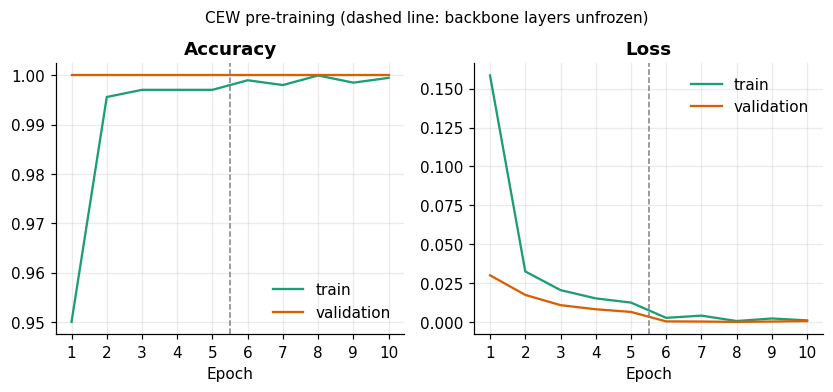

In [20]:
def cew_ds(subset):
    ds = keras.utils.image_dataset_from_directory(
        CEW, labels="inferred", label_mode="binary", class_names=["closed", "open"],
        image_size=(IMG, IMG), batch_size=BATCH, validation_split=0.15, subset=subset,
        seed=SEED, shuffle=True)
    return ds.prefetch(tf.data.AUTOTUNE)


cew_train, cew_val = cew_ds("training"), cew_ds("validation")

eye_base = make_backbone()
eye = build_model(eye_base, 1, "sigmoid")

set_trainable(eye_base, 0)
eye.compile(keras.optimizers.Adam(1e-3), "binary_crossentropy", metrics=["accuracy"])
h1 = eye.fit(cew_train, validation_data=cew_val, epochs=EPOCHS_CEW_HEAD, verbose=2)

set_trainable(eye_base, FINE_TUNE_LAYERS)
eye.compile(keras.optimizers.Adam(1e-5), "binary_crossentropy", metrics=["accuracy"])
h2 = eye.fit(cew_train, validation_data=cew_val, epochs=EPOCHS_CEW_FINE, verbose=2)

EYE_WEIGHTS = "eye_backbone.weights.h5"
eye_base.save_weights(EYE_WEIGHTS)
cew_val_acc = float(eye.evaluate(cew_val, verbose=0)[1])
print(f"\nCEW validation accuracy: {cew_val_acc:.3f}")

hist = {k: h1.history[k] + h2.history[k] for k in ["accuracy", "val_accuracy", "loss", "val_loss"]}
fig, axes = plt.subplots(1, 2, figsize=(9, 3.2))
epochs_axis = np.arange(1, len(hist["loss"]) + 1)
for ax, key, title in [(axes[0], "accuracy", "Accuracy"), (axes[1], "loss", "Loss")]:
    ax.plot(epochs_axis, hist[key], label="train", color="#1b9e77")
    ax.plot(epochs_axis, hist["val_" + key], label="validation", color="#d95f02")
    ax.axvline(EPOCHS_CEW_HEAD + 0.5, color="grey", ls="--", lw=1)
    ax.xaxis.set_major_locator(plt.MaxNLocator(integer=True))
    ax.set_title(title); ax.set_xlabel("Epoch"); ax.legend(frameon=False)
fig.suptitle("CEW pre-training (dashed line: backbone layers unfrozen)", y=1.03, fontsize=10)
savefig("cew_training_curves.png"); plt.show()

## 5. Stage 2: zero-shot evaluation on own participants

The CEW-trained model has not seen any of the project's photographs. To test how well eye-state knowledge transfers, `awake` images are treated as eyes open and `sleeping` images as eyes closed. `drowsy` images are excluded here because they lie between the two states.

In [21]:
mask = y != 1                                   # awake or sleeping only
p_open = eye.predict(X[mask], verbose=0).ravel()
true_open = (y[mask] == 0).astype(int)
pred_open = (p_open > 0.5).astype(int)

zero_shot_acc = float(accuracy_score(true_open, pred_open))
print(f"Zero-shot accuracy (awake = open, sleeping = closed): {zero_shot_acc:.3f}\n")
print("Confusion matrix (rows: true, columns: predicted; order: closed, open)")
print(confusion_matrix(true_open, pred_open, labels=[0, 1]), "\n")

per_zs = (pd.DataFrame({"participant": persons[mask], "correct": pred_open == true_open})
          .groupby("participant")["correct"].mean().round(2).rename("accuracy"))
print(per_zs.to_string(), "\n")

mean_open = {c: float(eye.predict(X[y == i], verbose=0).mean()) for i, c in enumerate(CLASSES) if (y == i).any()}
print("Mean predicted probability of open eyes by class:")
print({k: round(v, 2) for k, v in mean_open.items()})

Zero-shot accuracy (awake = open, sleeping = closed): 0.529

Confusion matrix (rows: true, columns: predicted; order: closed, open)
[[ 1 24]
 [ 0 26]] 

participant
p01    0.62
p02    0.40
p03    0.50
p04    0.50
p05    0.57
p06    0.40
p07    0.40
p08    1.00
p09    0.40 

Mean predicted probability of open eyes by class:
{'awake': 1.0, 'drowsy': 1.0, 'sleeping': 0.92}


## 6. Stage 3: fine-tuning for three classes

A new three-class output layer is added on top of the pre-trained backbone and trained on the participants' photographs. Class weights compensate for unequal class sizes.

This section reports a single fixed split in which entire participants are assigned to training, validation or test. The test set is small, so this result is supplementary. The leave-one-person-out evaluation in the next section is the primary result.

Fixed split (test: p02, p08; n = 13)
              precision    recall  f1-score   support

       awake       1.00      0.67      0.80         6
      drowsy       0.67      1.00      0.80         4
    sleeping       1.00      1.00      1.00         3

    accuracy                           0.85        13
   macro avg       0.89      0.89      0.87        13
weighted avg       0.90      0.85      0.85        13



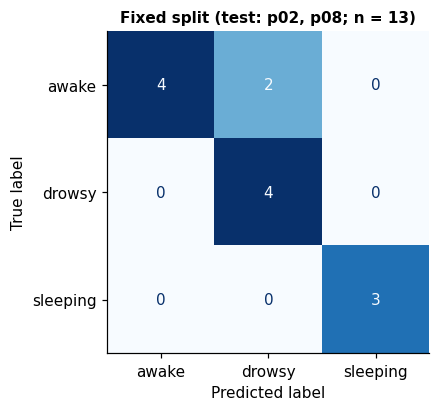

In [22]:
def class_weights(ytr):
    counts = np.bincount(ytr, minlength=3).astype(float)
    return {i: (len(ytr) / (3 * counts[i])) if counts[i] > 0 else 1.0 for i in range(3)}


def train_three_class(Xtr, ytr, Xva=None, yva=None, backbone_weights=None, verbose=0):
    base = make_backbone()
    if backbone_weights:
        base.load_weights(backbone_weights)
    model = build_model(base, 3, "softmax")
    val = (Xva, yva) if Xva is not None and len(Xva) else None
    cbs = [keras.callbacks.EarlyStopping(patience=5, restore_best_weights=True)] if val else []
    cw = class_weights(ytr)

    set_trainable(base, 0)
    model.compile(keras.optimizers.Adam(1e-3), "sparse_categorical_crossentropy", metrics=["accuracy"])
    model.fit(Xtr, ytr, validation_data=val, batch_size=BATCH, epochs=EPOCHS_OWN_HEAD,
              class_weight=cw, callbacks=cbs, verbose=verbose)

    set_trainable(base, FINE_TUNE_LAYERS)
    model.compile(keras.optimizers.Adam(1e-5), "sparse_categorical_crossentropy", metrics=["accuracy"])
    model.fit(Xtr, ytr, validation_data=val, batch_size=BATCH, epochs=EPOCHS_OWN_FINE,
              class_weight=cw, callbacks=cbs, verbose=verbose)
    return model


def show_results(y_true, y_pred, title, fname):
    print(title)
    print(classification_report(y_true, y_pred, labels=[0, 1, 2], target_names=CLASSES, zero_division=0))
    cm = confusion_matrix(y_true, y_pred, labels=[0, 1, 2])
    fig, ax = plt.subplots(figsize=(4.4, 3.8))
    ConfusionMatrixDisplay(cm, display_labels=CLASSES).plot(cmap="Blues", ax=ax, colorbar=False)
    ax.grid(False); ax.set_title(title, fontsize=10)
    savefig(fname); plt.show()


tr, va, te = splits == "train", splits == "val", splits == "test"
keras.backend.clear_session()
model = train_three_class(X[tr], y[tr], X[va], y[va], backbone_weights=EYE_WEIGHTS)
pred_fixed = model.predict(X[te], verbose=0).argmax(1)
fixed_acc = float(accuracy_score(y[te], pred_fixed))
show_results(y[te], pred_fixed,
             f"Fixed split (test: {', '.join(sorted(set(persons[te])))}; n = {int(te.sum())})",
             "confusion_fixed_split.png")

## 7. Leave-one-person-out evaluation

For each participant in turn, a model is trained on all other participants and tested on the held-out participant. Every image is therefore predicted by a model that has never seen that person, which gives the most reliable estimate available from this dataset.

The procedure is run twice: with the CEW pre-trained backbone, and with the ImageNet backbone only. The difference indicates whether the public data helped. A majority-class guess is included as a reference baseline.

ImageNet + CEW pre-training: done (9 folds)
ImageNet only: done (9 folds)

Leave-one-person-out results (all images pooled)
                     method  accuracy  macro_F1
    Majority-class baseline     0.338     0.168
              ImageNet only     0.714     0.709
ImageNet + CEW pre-training     0.688     0.679 

Leave-one-person-out (with CEW pre-training)
              precision    recall  f1-score   support

       awake       0.56      0.69      0.62        26
      drowsy       0.56      0.38      0.45        26
    sleeping       0.93      1.00      0.96        25

    accuracy                           0.69        77
   macro avg       0.68      0.69      0.68        77
weighted avg       0.68      0.69      0.68        77



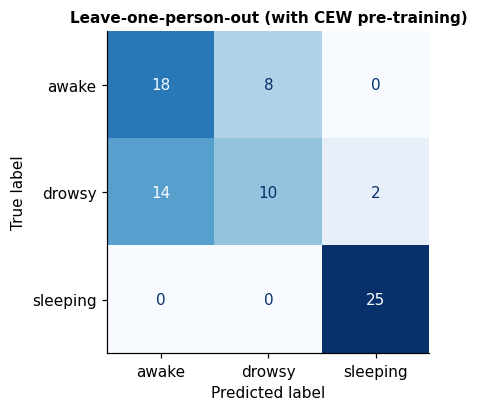

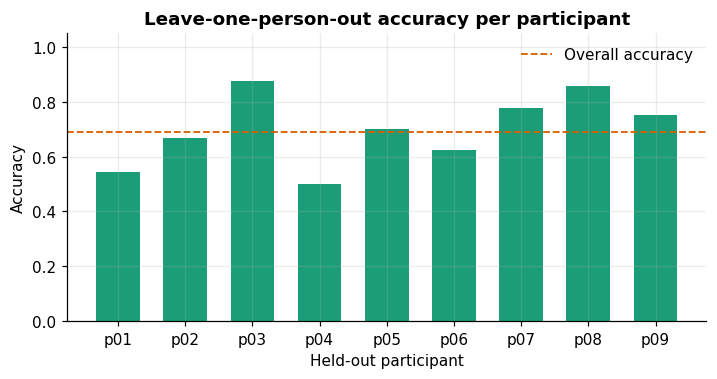

In [23]:
def run_lopo(backbone_weights, label):
    pred = np.full(len(y), -1)
    for p in sorted(set(persons)):
        held = persons == p
        keras.backend.clear_session()
        mdl = train_three_class(X[~held], y[~held], backbone_weights=backbone_weights)
        pred[held] = mdl.predict(X[held], verbose=0).argmax(1)
    print(f"{label}: done ({len(set(persons))} folds)")
    return pred


pred_cew = run_lopo(EYE_WEIGHTS, "ImageNet + CEW pre-training")
pred_plain = run_lopo(None, "ImageNet only")
pred_major = np.full(len(y), np.bincount(y).argmax())

rows = []
for name, pr in [("Majority-class baseline", pred_major),
                 ("ImageNet only", pred_plain),
                 ("ImageNet + CEW pre-training", pred_cew)]:
    rows.append({"method": name,
                 "accuracy": accuracy_score(y, pr),
                 "macro_F1": f1_score(y, pr, average="macro", labels=[0, 1, 2], zero_division=0)})
results = pd.DataFrame(rows).round(3)
print("\nLeave-one-person-out results (all images pooled)")
print(results.to_string(index=False), "\n")

show_results(y, pred_cew, "Leave-one-person-out (with CEW pre-training)", "confusion_lopo.png")

per_person = (pd.DataFrame({"participant": persons, "correct": pred_cew == y})
              .groupby("participant")["correct"].mean())
fig, ax = plt.subplots(figsize=(7.5, 3.4))
ax.bar(per_person.index, per_person.values, color="#1b9e77", width=0.65)
ax.axhline(accuracy_score(y, pred_cew), color="#d95f02", ls="--", lw=1.2, label="Overall accuracy")
ax.set_ylim(0, 1.05); ax.set_xlabel("Held-out participant"); ax.set_ylabel("Accuracy")
ax.set_title("Leave-one-person-out accuracy per participant"); ax.legend(frameon=False)
savefig("lopo_per_participant.png"); plt.show()

## 8. Summary and limitations

In [24]:
acc_c = float(results.loc[results.method == "ImageNet + CEW pre-training", "accuracy"].iloc[0])
acc_p = float(results.loc[results.method == "ImageNet only", "accuracy"].iloc[0])
f1_c = float(results.loc[results.method == "ImageNet + CEW pre-training", "macro_F1"].iloc[0])
f1_p = float(results.loc[results.method == "ImageNet only", "macro_F1"].iloc[0])

summary = pd.DataFrame([
    ("CEW validation (open vs closed)", "accuracy", cew_val_acc, "Training sanity check only"),
    ("Zero-shot on own participants (awake vs sleeping)", "accuracy", zero_shot_acc, "No own data used for training"),
    ("Fixed person split, 3 classes", "accuracy", fixed_acc, "Small test set; supplementary"),
    ("Leave-one-person-out, ImageNet only", "accuracy", acc_p, "Primary result"),
    ("Leave-one-person-out, ImageNet + CEW", "accuracy", acc_c, "Primary result"),
], columns=["Evaluation", "Metric", "Value", "Note"])
summary["Value"] = summary["Value"].round(3)
print(summary.to_string(index=False))
print(f"\nEffect of CEW pre-training: {acc_c - acc_p:+.3f} accuracy, {f1_c - f1_p:+.3f} macro-F1 "
      f"({len(y)} images, {df['person'].nunique()} participants). "
      "Differences of a few points are within the noise expected at this sample size.")

                                       Evaluation   Metric  Value                          Note
                  CEW validation (open vs closed) accuracy  1.000    Training sanity check only
Zero-shot on own participants (awake vs sleeping) accuracy  0.529 No own data used for training
                    Fixed person split, 3 classes accuracy  0.846 Small test set; supplementary
              Leave-one-person-out, ImageNet only accuracy  0.714                Primary result
             Leave-one-person-out, ImageNet + CEW accuracy  0.688                Primary result

Effect of CEW pre-training: -0.026 accuracy, -0.030 macro-F1 (77 images, 9 participants). Differences of a few points are within the noise expected at this sample size.


### Limitations

- **Small dataset.** The own data comprises a small number of images from nine participants, so all estimates carry wide uncertainty and individual participants can change results noticeably.
- **Uneven class coverage.** Not every participant has images in every class, which limits what can be learned and tested for those participants.
- **Framing.** Own photographs were centre-cropped rather than cropped to the face, whereas CEW images are face-centred. This difference in framing can reduce how well pre-training transfers.
- **Source differences in CEW.** Open-eye and closed-eye images in CEW come from different sources, so a model may partly learn image style rather than eye state. Zero-shot results on own participants are therefore the more meaningful check.
- **Subjective labels.** The boundary between drowsy and sleeping was decided by visual inspection and is inherently subjective.
- **Single-frame classification.** The model classifies one image at a time. The live WakeWatch application adds timing logic (eyes closed for about one second suggests drowsiness; about three seconds suggests sleep) to avoid reacting to normal blinks.
- **Demographic coverage.** Performance on groups that are under-represented in the training data has not been established. Per-participant results should be reviewed before any deployment.

### Ethical considerations

The system observes people. Any deployment should be transparent to those observed, process video locally, avoid storing footage by default, announce neutral alerts that do not identify individuals, and follow institutional policy and consent requirements.

## 9. Export

The final model is trained on all participants and saved for use in the WakeWatch application. Its accuracy should not be quoted, because it has seen every participant. The leave-one-person-out results above are the performance estimate.

In [25]:
keras.backend.clear_session()
final = train_three_class(X, y, backbone_weights=EYE_WEIGHTS)

os.makedirs("outputs", exist_ok=True)
final.save("outputs/wakewatch_model.keras")
json.dump(CLASSES, open("outputs/class_names.json", "w"))
results.to_csv("outputs/results_lopo.csv", index=False)
summary.to_csv("outputs/results_summary.csv", index=False)
print(f"Model saved ({final.count_params():,} parameters). Files in outputs/:", sorted(os.listdir("outputs")))

Model saved (2,261,827 parameters). Files in outputs/: ['class_names.json', 'figures', 'results_lopo.csv', 'results_summary.csv', 'wakewatch_model.keras']


In [26]:
import shutil
shutil.copytree("outputs", os.path.join(DRIVE, "outputs"), dirs_exist_ok=True)
print("Copied to Google Drive:", os.path.join(DRIVE, "outputs"))

Copied to Google Drive: /content/drive/MyDrive/wakewatch/outputs


## 10. References

1. Sandler, M., Howard, A., Zhu, M., Zhmoginov, A., and Chen, L.-C. (2018). MobileNetV2: Inverted Residuals and Linear Bottlenecks. *IEEE/CVF Conference on Computer Vision and Pattern Recognition (CVPR)*.
2. Song, F., Tan, X., Liu, X., and Chen, S. (2014). Eyes closeness detection from still images with multi-scale histograms of principal oriented gradients. *Pattern Recognition*, 47(9), 2825-2838. (CEW dataset.)
3. Huang, G. B., Ramesh, M., Berg, T., and Learned-Miller, E. (2007). Labeled Faces in the Wild: A Database for Studying Face Recognition in Unconstrained Environments. University of Massachusetts, Amherst, Technical Report 07-49.
4. Deng, J., Dong, W., Socher, R., Li, L.-J., Li, K., and Fei-Fei, L. (2009). ImageNet: A large-scale hierarchical image database. *IEEE CVPR*.

The CEW dataset is licensed for non-commercial research and educational use only.